# 33. Test results: old pick, near and both (reporting seeds)

Notebook 32 compared four ways of giving the model its skeletons on validation (tuning seeds 77 and 88): the single skeleton of the old pipeline, the near player, the far player and both.
`both` was about 5 points top-1 and 5 points MCA above the old pick; the near player alone was level with it. This notebook produces the reported numbers for the arms that matter, on the **test set with the reporting seeds 42, 123 and 7**.

| arm | skeleton(s) the model sees |
|---|---|
| `old_pick` | the single skeleton of the old pipeline (`keypoints_interp`) |
| `near` | the player nearer the camera (new pipeline) |
| `both` | both players, the same ST-GCN weights per player, features concatenated in the fixed order (near, far) |

The far player alone (`far`) was weaker than the near player on validation (70.4 against 75.4) and is not rerun here.

**Order of work**
1. Settings, smoke test.
2. **Tuning for `both` (validation only).** The recipe in `configs/stgcn_recipe.json` was tuned for a single player. `both` has twice the input and a 512 dimensional head, so it may prefer a different learning rate, weight decay or schedule. Five single changes from the base recipe are tried on the tuning seeds 77 and 88, using train and validation only; **the test set is never touched here**. A change is adopted only if it clears the decision rule below, otherwise `both` keeps the base recipe.
3. **Reporting runs.** Set `RUN_ARMS = ["both"]` first (3 runs), then `["near", "old_pick"]`. The analysis cells work with whichever arms are finished.

Everything else is as in notebook 32: the same clips (present in both datasets), same split, ST-GCN of mmaction2, `body_court` input, advanced online augmentation, natural class frequencies, checkpoint selected on the validation composite (mean of val top-1 and MCA). The test set is evaluated once per run, at the end, and never used to choose anything.
The model sees only pose. Outputs: mean and standard deviation over seeds, paired bootstrap intervals over test clips for the differences that matter, recall for the limited sample classes, a per class table and accuracy by subset.

The control experiments (what the gain depends on) are in notebook 34 and are not needed here.

In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from clearml import Task

REPO = os.environ.get("BADMINTON_REPO", "/workspace/badminton-honours-project")
DATA = os.environ.get("BADMINTON_DATA", "/workspace/data")
OUTPUTS = os.environ.get("BADMINTON_OUTPUTS", "/workspace/outputs")
for p in (REPO, f"{REPO}/two_player"):
    sys.path.insert(0, p)
import dataset as ds
import training as tr
import two_person as tp

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__, device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

2.1.0+cu118 cuda NVIDIA GeForce RTX 4090


In [2]:
PROJECT = "BadmintonPoseAnalysis/experiments/two_player_test"
OLD_KP = f"{DATA}/keypoints_interp"
SEL_INTERP = f"{DATA}/keypoints_sel_interp"
OUT = f"{OUTPUTS}/experiments/two_player_test"
os.makedirs(OUT, exist_ok=True)

REPORT_SEEDS = [42, 123, 7]
SELECT_METRIC = "composite"
NORMALISATION, USE_COURT = "body", True
NUM_WORKERS, EVAL_WORKERS = 20, 8
FAR_COVERAGE_MIN = 0.5
DRILL_PATTERN = r"2023"
RARE_THRESHOLD = 150
N_BOOT = 2000

# tuning stage (validation only, tuning seeds, never the test set)
TUNE_ARMS = ["both"]          # arms whose recipe is tuned. Add "near" for an equal tuning budget
TUNE_SEEDS = [77, 88]
TUNE_GRID = {                 # one change at a time from the base recipe
    "lr0.005": {"lr": 0.005},
    "lr0.02": {"lr": 0.02},
    "wd0.002": {"weight_decay": 2e-3},
    "wd0.01": {"weight_decay": 1e-2},
    "slow_sched": {"step_size": 15, "gamma": 0.3},
}
TUNE_MIN_GAIN = 0.5           # points of mean val top-1 over base needed to switch
TUNE_MAX_MCA_DROP = 1.0       # and mean val MCA may not fall more than this (points)
OUT_TUNE = f"{OUTPUTS}/experiments/two_player_tune"
os.makedirs(OUT_TUNE, exist_ok=True)
TEST_ARMS = {"old_pick": dict(root=OLD_KP, persons=(0,)), "near": dict(root=SEL_INTERP, persons=(0,)),
             "both": dict(root=SEL_INTERP, persons=(0, 1))}

with open(f"{REPO}/configs/stgcn_recipe.json") as f:
    RECIPE = json.load(f)
FINAL_RECIPE_NAME = {a: "base" for a in TEST_ARMS}       # updated by the selection cell
FINAL_RECIPE = {a: dict(RECIPE) for a in TEST_ARMS}
split_hash = open(f"{DATA}/split_manifest.sha256").read().split()[0]

clean_log = pd.read_csv(f"{DATA}/keypoints_sel_interp_log.csv").set_index("filepath")
manifest = ds.load_filtered_manifest(f"{DATA}/split_manifest.csv", f"{DATA}/extraction_log.csv",
                                     f"{DATA}/keypoints_interp_log.csv", RECIPE["min_native_frames"])
manifest = manifest[manifest["filepath"].isin(clean_log.index)].reset_index(drop=True)
manifest = manifest[clean_log.loc[manifest["filepath"], "near_cov"].to_numpy() > 0].reset_index(drop=True)
manifest["far_found"] = clean_log.loc[manifest["filepath"], "far_cov"].to_numpy() >= FAR_COVERAGE_MIN
manifest["drill"] = manifest["filepath"].str.contains(DRILL_PATTERN)
class_names = sorted(manifest["class_name"].unique())
class_to_id = {c: i for i, c in enumerate(class_names)}
K = len(class_names)
IN_CH = tp.n_channels(USE_COURT)
train_counts = manifest[manifest["split"] == "train"]["class_name"].value_counts().reindex(class_names)
rare_names = [c for c in class_names if train_counts[c] < RARE_THRESHOLD]
print(manifest["split"].value_counts().to_dict(), f"| {K} classes | {len(rare_names)} limited sample classes (under {RARE_THRESHOLD} train clips)")

manual review: dropped 4 clips
short clip rule: dropped 4 train clips with fewer than 5 real frames
7810 clips remain (train 6247, test 782, val 781)
{'train': 6247, 'test': 782, 'val': 781} | 18 classes | 8 limited sample classes (under 150 train clips)


## Smoke test

Each arm builds and runs, and the data has the expected shapes. Run this cell alone first.

In [3]:
tr.seed_everything(0)
rows = []
for arm, cfg in TEST_ARMS.items():
    loaders = tp.build_loaders(manifest, cfg["root"], class_to_id, cfg["persons"], "advanced", seed=0, batch_size=RECIPE["batch_size"],
                               num_workers=2, eval_workers=2, splits=("train", "val", "test"))
    batch = next(iter(loaders["train"]))
    assert batch["keypoints"].shape[1:] == (len(cfg["persons"]), 30, 17, 3), batch["keypoints"].shape
    model = tp.PersonsSTGCN(IN_CH, K, len(cfg["persons"])).to(device)
    logits = tp.make_forward(USE_COURT)(model, batch, device)
    assert logits.shape == (len(batch["label"]), K)
    nn.CrossEntropyLoss(label_smoothing=RECIPE["label_smoothing"])(logits, batch["label"].to(device)).backward()
    rows.append({"arm": arm, "persons": cfg["persons"], "test clips": len(loaders["test"].dataset)})
    del model, loaders
print(pd.DataFrame(rows).to_string(index=False))
print("smoke test passed")

     arm persons  test clips
old_pick    (0,)         782
    near    (0,)         782
    both  (0, 1)         782
smoke test passed


## Training

In [4]:
def run_name_of(prefix, arm, recipe_name, seed):
    mid = "" if recipe_name == "base" else f"_{recipe_name}"
    return f"{prefix}_{arm}{mid}_s{seed}"


def run_arm(arm, cfg, seed, results_path, done, splits, tag, recipe=None, recipe_name="base", out_root=None, prefix="t33", donors=None):
    recipe = RECIPE if recipe is None else recipe
    out_root = OUT if out_root is None else out_root
    rn_col = done["recipe_name"].fillna("base") if "recipe_name" in done.columns else pd.Series("base", index=done.index)
    if ((done["arm"] == arm) & (done["seed"] == seed) & (rn_col == recipe_name)).any():
        print(f"skip {arm} {recipe_name} seed {seed}")
        return done
    run_name = run_name_of(prefix, arm, recipe_name, seed)
    print(f"\n=== {run_name} ===")
    tr.seed_everything(seed)
    task = Task.init(project_name=PROJECT, task_name=run_name, task_type=Task.TaskTypes.training,
                     tags=["two_player", "test_results", tag, arm, recipe_name, f"seed{seed}"], reuse_last_task_id=False,
                     auto_connect_frameworks={"matplotlib": False, "pytorch": False})
    task.connect({**recipe, "arm": arm, "recipe_name": recipe_name, "persons": list(cfg["persons"]), "seed": seed, "select_metric": SELECT_METRIC,
                  "balanced": False, "policy": "advanced", "n_clips": len(manifest), "evaluated_splits": list(splits),
                  "shuffled_far": donors is not None, "split_sha256": split_hash})
    loaders = tp.build_loaders(manifest, cfg["root"], class_to_id, cfg["persons"], "advanced", seed=seed,
                               batch_size=recipe["batch_size"], num_workers=NUM_WORKERS, eval_workers=EVAL_WORKERS,
                               splits=splits, donors=donors)
    model = tp.PersonsSTGCN(IN_CH, K, len(cfg["persons"])).to(device)
    forward = tp.make_forward(USE_COURT)
    optimizer = torch.optim.SGD(model.parameters(), lr=recipe["lr"], momentum=recipe["momentum"], weight_decay=recipe["weight_decay"])
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=recipe.get("step_size", 10), gamma=recipe["gamma"])
    criterion = nn.CrossEntropyLoss(label_smoothing=recipe["label_smoothing"])
    _, history, best_epoch = tr.train_model(model, forward, loaders, optimizer, scheduler, criterion, device,
                                            task.get_logger(), num_epochs=recipe["num_epochs"], patience=recipe.get("patience", 20),
                                            select_metric=SELECT_METRIC, splits=splits)
    metrics = tr.report_run(task, model, forward, loaders, class_names, device, history, best_epoch,
                            out_dir=f"{out_root}/{run_name}", run_name=run_name, splits=splits, show=False,
                            extra={"arm": arm, "seed": seed, "recipe_name": recipe_name})
    task.close()
    done = pd.concat([done, pd.DataFrame([metrics])], ignore_index=True)
    done.to_csv(results_path, index=False)
    del model, loaders
    torch.cuda.empty_cache()
    return done

## Tuning for `both` (validation only)

Skip this section by setting `TUNE_ARMS = []` in the settings cell. Runs use train and validation only and the tuning seeds, so the reporting seeds and the test set stay untouched.
The base rows are taken from notebook 32 (same data, recipe, seeds) when its `results.csv` is present, so the base recipe is not trained again.

In [5]:
tune_path = f"{OUT_TUNE}/results_tune.csv"
tune_done = pd.read_csv(tune_path) if os.path.exists(tune_path) else pd.DataFrame(columns=["arm", "seed", "recipe_name"])
prev_path = f"{OUTPUTS}/experiments/two_player/results.csv"
if os.path.exists(prev_path):
    prev = pd.read_csv(prev_path)
    if {"arm", "seed", "val_top1", "val_mca"} <= set(prev.columns):
        prev = prev[prev["arm"].isin(TUNE_ARMS) & prev["seed"].isin(TUNE_SEEDS)].assign(recipe_name="base")
        have = set(zip(tune_done["arm"], tune_done["seed"], tune_done["recipe_name"].fillna("base")))
        prev = prev[[(a, s, "base") not in have for a, s in zip(prev["arm"], prev["seed"])]]
        if len(prev):
            tune_done = pd.concat([tune_done, prev], ignore_index=True)
            tune_done.to_csv(tune_path, index=False)
            print(f"reused {len(prev)} base runs from notebook 32")

for arm in TUNE_ARMS:
    for name, override in {"base": {}, **TUNE_GRID}.items():
        for seed in TUNE_SEEDS:
            tune_done = run_arm(arm, TEST_ARMS[arm], seed, tune_path, tune_done, ("train", "val"), "tune",
                                recipe={**RECIPE, **override}, recipe_name=name, out_root=OUT_TUNE, prefix="tune33")

reused 2 base runs from notebook 32
skip both base seed 77
skip both base seed 88

=== tune33_both_lr0.005_s77 ===
ClearML Task: created new task id=59c3f5622b704a33848f6497be6e82e4
2026-10-10 03:21:19,350 - clearml.Repository Detection - WARNING - Failed accessing the jupyter server(s): []
ClearML results page: https://app.clear.ml/projects/62342df207cf45aeb8bbaad37b977663/tasks/59c3f5622b704a33848f6497be6e82e4/output/log
epoch   0  loss 1.708  train 0.606  val 0.597 (mca 0.418)  *
epoch   1  loss 1.153  train 0.699  val 0.684 (mca 0.502)  *
epoch   2  loss 1.015  train 0.728  val 0.713 (mca 0.529)  *
epoch   3  loss 0.932  train 0.751  val 0.713 (mca 0.544)  *
epoch   5  loss 0.851  train 0.775  val 0.750 (mca 0.547)  *
epoch   6  loss 0.805  train 0.785  val 0.758 (mca 0.586)  *
epoch  10  loss 0.593  train 0.846  val 0.772 (mca 0.632)  *
epoch  11  loss 0.536  train 0.860  val 0.784 (mca 0.636)  *
epoch  12  loss 0.518  train 0.866  val 0.789 (mca 0.662)  *
epoch  15  loss 0.463  t

███████████████████████████████ 100% | 11.68/11.68 MB [00:01<00:00,  9.62MB/s]: 



=== tune33_both_lr0.005_s88 ===


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=688f21d9142d453095dc3811c316f7e0
ClearML results page: https://app.clear.ml/projects/62342df207cf45aeb8bbaad37b977663/tasks/688f21d9142d453095dc3811c316f7e0/output/log
epoch   0  loss 1.702  train 0.644  val 0.645 (mca 0.421)  *
epoch   1  loss 1.134  train 0.699  val 0.693 (mca 0.499)  *
epoch   3  loss 0.920  train 0.759  val 0.730 (mca 0.548)  *
epoch   4  loss 0.851  train 0.776  val 0.753 (mca 0.580)  *
epoch   5  loss 0.808  train 0.770  val 0.749 (mca 0.583)
epoch   7  loss 0.780  train 0.802  val 0.752 (mca 0.600)  *
epoch   9  loss 0.734  train 0.810  val 0.758 (mca 0.600)  *
epoch  10  loss 0.581  train 0.853  val 0.791 (mca 0.650)  *
epoch  15  loss 0.451  train 0.893  val 0.784 (mca 0.652)
epoch  16  loss 0.431  train 0.900  val 0.796 (mca 0.677)  *
epoch  20  loss 0.337  train 0.936  val 0.796 (mca 0.674)
epoch  24  loss 0.302  train 0.945  val 0.799 (mca 0.683)  *
epoch  25  loss 0.293  train 0.947  val 0.802 (mca 0.677)
epoch  26  loss 0

...

███████████████████████████████ 100% | 11.68/11.68 MB [00:01<00:00,  9.45MB/s]: 



=== tune33_both_slow_sched_s88 ===


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=0f1cfd1283b640fb8c3789dfa2eecc59
ClearML results page: https://app.clear.ml/projects/62342df207cf45aeb8bbaad37b977663/tasks/0f1cfd1283b640fb8c3789dfa2eecc59/output/log
epoch   0  loss 1.807  train 0.648  val 0.643 (mca 0.399)  *
epoch   1  loss 1.202  train 0.695  val 0.679 (mca 0.476)  *
epoch   3  loss 0.972  train 0.730  val 0.702 (mca 0.510)  *
epoch   4  loss 0.914  train 0.757  val 0.734 (mca 0.559)  *
epoch   5  loss 0.888  train 0.749  val 0.720 (mca 0.523)
epoch   7  loss 0.861  train 0.758  val 0.735 (mca 0.560)  *
epoch   9  loss 0.842  train 0.776  val 0.743 (mca 0.568)  *
epoch  10  loss 0.835  train 0.764  val 0.743 (mca 0.556)
epoch  11  loss 0.820  train 0.766  val 0.741 (mca 0.589)  *
epoch  13  loss 0.802  train 0.767  val 0.748 (mca 0.603)  *
epoch  15  loss 0.669  train 0.826  val 0.776 (mca 0.638)  *
epoch  17  loss 0.615  train 0.841  val 0.799 (mca 0.661)  *
epoch  20  loss 0.602  train 0.839  val 0.781 (mca 0.632)
epoch  25  los

███████████████████████████████ 100% | 11.68/11.68 MB [00:01<00:00,  9.84MB/s]: 


In [6]:
FINAL_RECIPE_NAME = {a: "base" for a in TEST_ARMS}
FINAL_RECIPE = {a: dict(RECIPE) for a in TEST_ARMS}
tuning_summary = {}
if TUNE_ARMS and os.path.exists(tune_path):
    td = pd.read_csv(tune_path)
    td["recipe_name"] = td["recipe_name"].fillna("base")
    vcols = [c for c in ("val_top1", "val_top5", "val_mca", "val_macro_f1") if c in td.columns]
    td["val_composite"] = (td["val_top1"] + td["val_mca"]) / 2
    summ = (td.groupby(["arm", "recipe_name"])[vcols + ["val_composite"]].mean() * 100).round(2)
    summ["n seeds"] = td.groupby(["arm", "recipe_name"]).size()
    for arm in TUNE_ARMS:
        s = summ.loc[arm]
        if "base" not in s.index or s.loc["base", "n seeds"] < len(TUNE_SEEDS):
            print(f"{arm}: base not complete on the tuning seeds, keeping the base recipe")
            continue
        ok = s[(s["n seeds"] == len(TUNE_SEEDS)) & (s.index != "base")
               & (s["val_top1"] >= s.loc["base", "val_top1"] + TUNE_MIN_GAIN)
               & (s["val_mca"] >= s.loc["base", "val_mca"] - TUNE_MAX_MCA_DROP)]
        if len(ok):
            best = ok["val_composite"].idxmax()
            FINAL_RECIPE_NAME[arm] = best
            FINAL_RECIPE[arm] = {**RECIPE, **TUNE_GRID[best]}
        tuning_summary[arm] = FINAL_RECIPE_NAME[arm]
        print(f"{arm}: final recipe = {FINAL_RECIPE_NAME[arm]}")
    with open(f"{REPO}/configs/two_player_tuned.json", "w") as f:
        json.dump({"tune_seeds": TUNE_SEEDS, "selected": FINAL_RECIPE_NAME, "grid": TUNE_GRID,
                   "min_gain": TUNE_MIN_GAIN, "max_mca_drop": TUNE_MAX_MCA_DROP,
                   "validation_means": summ.reset_index().to_dict(orient="records")}, f, indent=2, default=str)
    display(summ)
else:
    print("no tuning results, every arm uses the base recipe")

both: final recipe = slow_sched


val_top1  val_top5  val_mca  val_macro_f1  val_composite  \
arm  recipe_name                                                             
both base            79.51     95.97    67.61         69.72          73.56   
     lr0.005         79.96     96.16    68.73         70.92          74.34   
     lr0.02          79.83     96.54    65.62         67.47          72.73   
     slow_sched      80.35     96.22    69.49         71.98          74.92   
     wd0.002         80.35     96.09    68.73         71.21          74.54   
     wd0.01          80.22     96.22    65.42         66.76          72.82   

                  n seeds  
arm  recipe_name           
both base               2  
     lr0.005            2  
     lr0.02             2  
     slow_sched         2  
     wd0.002            2  
     wd0.01             2

## Reporting runs

`RUN_ARMS = ["both"]` first, then `["near", "old_pick"]`. Runs already in `results_test.csv` for the same arm, seed and recipe are skipped, so this can be stopped and resumed.
Each arm uses the recipe chosen above (`FINAL_RECIPE`), which is the base recipe unless tuning found a clear gain.

In [7]:
RUN_ARMS = ["both"]          # run both first; then ["near", "old_pick"]

test_path = f"{OUT}/results_test.csv"
test_done = pd.read_csv(test_path) if os.path.exists(test_path) else pd.DataFrame(columns=["arm", "seed", "recipe_name"])
for arm in RUN_ARMS:
    for seed in REPORT_SEEDS:
        test_done = run_arm(arm, TEST_ARMS[arm], seed, test_path, test_done, ("train", "val", "test"), "test",
                            recipe=FINAL_RECIPE[arm], recipe_name=FINAL_RECIPE_NAME[arm])


=== t33_both_slow_sched_s42 ===


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=5bef61b060f34c2091c7857c78418896
ClearML results page: https://app.clear.ml/projects/62342df207cf45aeb8bbaad37b977663/tasks/5bef61b060f34c2091c7857c78418896/output/log
epoch   0  loss 1.709  train 0.616  val 0.606 (mca 0.391)  *
epoch   1  loss 1.166  train 0.687  val 0.671 (mca 0.472)  *
epoch   2  loss 1.023  train 0.743  val 0.716 (mca 0.513)  *
epoch   3  loss 0.972  train 0.716  val 0.698 (mca 0.545)  *
epoch   5  loss 0.901  train 0.748  val 0.718 (mca 0.531)  *
epoch   6  loss 0.875  train 0.774  val 0.743 (mca 0.586)  *
epoch  10  loss 0.838  train 0.774  val 0.743 (mca 0.539)
epoch  15  loss 0.680  train 0.826  val 0.775 (mca 0.626)  *
epoch  17  loss 0.616  train 0.840  val 0.772 (mca 0.629)  *
epoch  19  loss 0.606  train 0.838  val 0.789 (mca 0.649)  *
epoch  20  loss 0.602  train 0.831  val 0.766 (mca 0.623)
epoch  25  loss 0.560  train 0.853  val 0.789 (mca 0.654)  *
epoch  27  loss 0.535  train 0.858  val 0.789 (mca 0.670)  *
epoch  30  

███████████████████████████████ 100% | 11.68/11.68 MB [00:01<00:00,  8.49MB/s]: 



=== t33_both_slow_sched_s123 ===


...

███████████████████████████████ 100% | 11.68/11.68 MB [00:01<00:00,  8.44MB/s]: 



=== t33_both_slow_sched_s7 ===


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=edbd8834a5d64edfac0d026073197dc9
ClearML results page: https://app.clear.ml/projects/62342df207cf45aeb8bbaad37b977663/tasks/edbd8834a5d64edfac0d026073197dc9/output/log
epoch   0  loss 1.694  train 0.616  val 0.611 (mca 0.401)  *
epoch   1  loss 1.169  train 0.663  val 0.638 (mca 0.411)  *
epoch   2  loss 1.039  train 0.691  val 0.644 (mca 0.469)  *
epoch   3  loss 0.963  train 0.740  val 0.720 (mca 0.534)  *
epoch   4  loss 0.921  train 0.749  val 0.709 (mca 0.565)  *
epoch   5  loss 0.893  train 0.727  val 0.700 (mca 0.576)  *
epoch   8  loss 0.836  train 0.763  val 0.743 (mca 0.568)  *
epoch  10  loss 0.823  train 0.770  val 0.723 (mca 0.577)
epoch  14  loss 0.809  train 0.770  val 0.744 (mca 0.588)  *
epoch  15  loss 0.674  train 0.827  val 0.781 (mca 0.631)  *
epoch  20  loss 0.586  train 0.830  val 0.763 (mca 0.599)
epoch  21  loss 0.588  train 0.838  val 0.770 (mca 0.645)  *
epoch  25  loss 0.563  train 0.860  val 0.771 (mca 0.639)
epoch  26  los

███████████████████████████████ 100% | 11.68/11.68 MB [00:01<00:00,  8.97MB/s]: 


In [8]:
rt = pd.read_csv(test_path)
rt["recipe_name"] = rt["recipe_name"].fillna("base") if "recipe_name" in rt.columns else "base"
rt = rt[[r == FINAL_RECIPE_NAME.get(a) for a, r in zip(rt["arm"], rt["recipe_name"])]].reset_index(drop=True)
ARMS = [a for a in TEST_ARMS if (rt["arm"] == a).sum() == len(REPORT_SEEDS)]
print("arms with all reporting seeds:", ARMS, "| recipes:", {a: FINAL_RECIPE_NAME[a] for a in ARMS})
tcols = ["test_top1", "test_top5", "test_mca", "test_macro_f1", "val_top1", "train_top1", "train_test_gap", "best_epoch"]
tm, ts = rt.groupby("arm")[tcols].mean().reindex(ARMS), rt.groupby("arm")[tcols].std().reindex(ARMS)
tshow = tm.copy()
for c in tcols:
    if c != "best_epoch":
        tshow[c] = (100 * tm[c]).round(2).astype(str) + " +/- " + (100 * ts[c]).round(2).astype(str)
tshow["best_epoch"] = tm["best_epoch"].round(1)
print("test set, mean +/- std over seeds", REPORT_SEEDS, "(points); Li et al. ST-GCN: top1 74.41, top5 93.76, MCA 61.44")
tshow

arms with all reporting seeds: ['both'] | recipes: {'both': 'slow_sched'}
test set, mean +/- std over seeds [42, 123, 7] (points); Li et al. ST-GCN: top1 74.41, top5 93.76, MCA 61.44


,test_top1,test_top5,test_mca,test_macro_f1,val_top1,train_top1,train_test_gap,best_epoch
arm,,,,,,,,
both,78.6 +/- 0.48,95.61 +/- 0.27,67.2 +/- 1.72,69.55 +/- 1.79,80.58 +/- 0.82,99.94 +/- 0.04,21.33 +/- 0.45,51.0


In [9]:
rt[["arm", "seed", "test_top1", "test_top5", "test_mca", "test_macro_f1"]].sort_values(["arm", "seed"]).assign(
    **{c: lambda d, c=c: (100 * d[c]).round(2) for c in ("test_top1", "test_top5", "test_mca", "test_macro_f1")})

,arm,seed,test_top1,test_top5,test_mca,test_macro_f1
4,both,7,78.26,95.91,65.65,68.13
2,both,42,78.39,95.40,66.89,68.96
3,both,123,79.16,95.52,69.05,71.56
1,near,42,72.89,94.37,55.78,56.47
0,old_pick,42,72.25,94.76,55.28,56.58


### Differences with intervals

Paired bootstrap over test clips: the same resampled clips are scored for both arms, for each seed, and the metric is averaged over the seeds.
The intervals reflect which test clips were drawn; they do not include seed to seed variation (three seeds), so a difference that is only just clear of zero should be read cautiously.

In [10]:
def load_preds(arm):
    out = {}
    for s in REPORT_SEEDS:
        rn = run_name_of("t33", arm, FINAL_RECIPE_NAME[arm], s)
        p = pd.read_csv(f"{OUT}/{rn}/{rn}_predictions.csv")
        p = p[p["split"] == "test"].sort_values("filepath").reset_index(drop=True)
        out[s] = p
    return out


P = {arm: load_preds(arm) for arm in ARMS}
files = P[ARMS[0]][REPORT_SEEDS[0]]["filepath"].to_numpy()
for arm in ARMS:
    for s in REPORT_SEEDS:
        assert (P[arm][s]["filepath"].to_numpy() == files).all()
y = P[ARMS[0]][REPORT_SEEDS[0]]["label"].map(class_to_id).to_numpy()
Y = {arm: {s: P[arm][s]["pred"].map(class_to_id).to_numpy() for s in REPORT_SEEDS} for arm in ARMS}


def top1(yt, yp):
    return float((yt == yp).mean())


def mca(yt, yp):
    tot = np.bincount(yt, minlength=K)
    hit = np.bincount(yt[yt == yp], minlength=K)
    return float((hit[tot > 0] / tot[tot > 0]).mean())


def seed_mean(arm, idx, fn):
    return float(np.mean([fn(y[idx], Y[arm][s][idx]) for s in REPORT_SEEDS]))


def boot_diff(a, b, fn, n_boot=N_BOOT, seed=0):
    rng = np.random.RandomState(seed)
    full = np.arange(len(y))
    point = seed_mean(a, full, fn) - seed_mean(b, full, fn)
    d = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.randint(0, len(y), len(y))
        d[i] = seed_mean(a, idx, fn) - seed_mean(b, idx, fn)
    lo, hi = np.percentile(d, [2.5, 97.5])
    return point, lo, hi


rows = []
for a, b in (("both", "near"), ("both", "old_pick"), ("near", "old_pick")):
    if a not in ARMS or b not in ARMS:
        continue
    row = {"comparison": f"{a} - {b}"}
    for fn, label in ((top1, "top1"), (mca, "mca")):
        pt, lo, hi = boot_diff(a, b, fn)
        row[f"{label} (pts)"] = round(100 * pt, 2)
        row[f"{label} 95% CI"] = f"[{100 * lo:+.2f}, {100 * hi:+.2f}]"
    rows.append(row)
diffs = pd.DataFrame(rows)
print("comparisons available:", list(diffs["comparison"]) if len(diffs) else "none yet (need two finished arms)")
diffs

comparisons available: none yet (need two finished arms)


""


### Where the gain lands

Recall for the limited sample classes (under 150 training clips) and the common classes, and per class recall for `near` and `both`.

In [11]:
def recall_by_class(arm):
    r = np.zeros((len(REPORT_SEEDS), K))
    for i, s in enumerate(REPORT_SEEDS):
        for k in range(K):
            m = y == k
            r[i, k] = (Y[arm][s][m] == k).mean() if m.any() else np.nan
    return r.mean(axis=0)


rec = pd.DataFrame({arm: recall_by_class(arm) for arm in ARMS}, index=[c.split("_", 1)[-1] for c in class_names])
rare_idx = [class_names.index(c) for c in rare_names]
common_idx = [k for k in range(K) if k not in rare_idx]
group = pd.DataFrame({arm: {"limited sample recall": rec[arm].iloc[rare_idx].mean(), "common recall": rec[arm].iloc[common_idx].mean()}
                      for arm in ARMS}).T
print(f"limited sample classes: {[c.split('_', 1)[-1] for c in rare_names]}")
(100 * group).round(2)

limited sample classes: ['Cross Court Flight', 'Tap Smash', 'Transitional Slice', 'Rush Shot', 'Defensive Clear', 'Defensive Drive', 'Rear Court Flat Drive', 'Short Flat Shot']


,limited sample recall,common recall
both,56.7,75.59


In [12]:
per_class = (100 * rec[ARMS]).round(1)
per_class["support"] = np.bincount(y, minlength=K)
if "both" in ARMS and "near" in ARMS:
    per_class["both - near"] = (per_class["both"] - per_class["near"]).round(1)
    per_class = per_class.sort_values("both - near", ascending=False)
per_class

,both,support
Short Serve,97.7,88
Cross Court Flight,39.6,16
Lift,75.9,76
Tap Smash,42.4,11
Block,80.6,31
Drop Shot,85.2,81
Push Shot,40.8,40
Transitional Slice,41.0,13
Cut,80.8,59
Rush Shot,69.4,12


In [13]:
test_part = manifest[manifest["split"] == "test"].set_index("filepath").loc[files]
subs = {"all": np.ones(len(files), bool), "far found": test_part["far_found"].to_numpy(), "far not found": ~test_part["far_found"].to_numpy(),
        "match clips": ~test_part["drill"].to_numpy(), "drill clips": test_part["drill"].to_numpy()}
rows = []
for arm in ARMS:
    row = {"arm": arm}
    for name, m in subs.items():
        row[name] = round(100 * float(np.mean([top1(y[m], Y[arm][s][m]) for s in REPORT_SEEDS])), 2)
    rows.append(row)
rows.append({"arm": "n clips", **{k: int(v.sum()) for k, v in subs.items()}})
test_subsets = pd.DataFrame(rows)
test_subsets

,arm,all,far found,far not found,match clips,drill clips
0,both,78.6,78.92,62.22,77.61,97.44
1,n clips,782.0,767.00,15.00,743.00,39.00


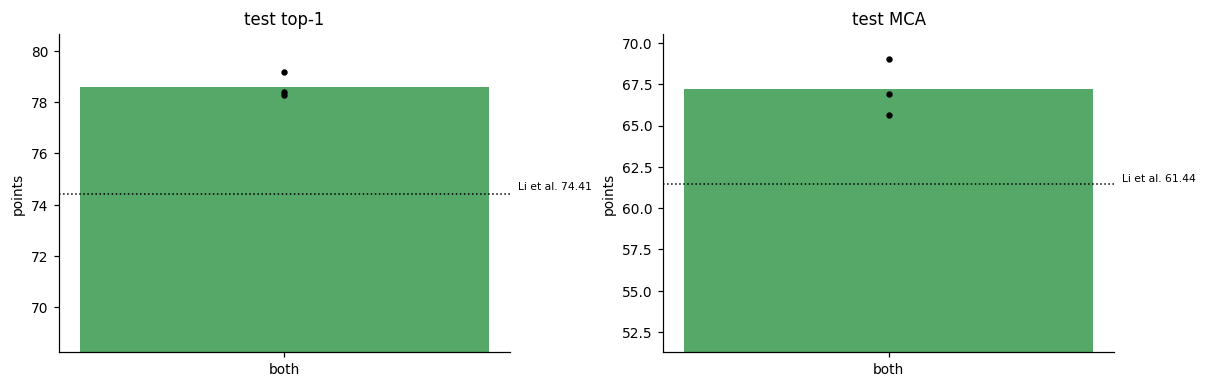

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
arm_colors = {"old_pick": "#b0b0b0", "near": "#4c72b0", "far": "#c44e52", "both": "#55a868"}
for ax, col, title in zip(axes, ("test_top1", "test_mca"), ("test top-1", "test MCA")):
    for j, arm in enumerate(ARMS):
        v = 100 * rt[rt["arm"] == arm][col].to_numpy()
        ax.bar(j, v.mean(), color=arm_colors[arm], width=0.6)
        ax.scatter([j] * len(v), v, color="k", s=10, zorder=3)
    ax.set_xticks(range(len(ARMS)), ARMS)
    ax.set_ylim(100 * rt[col].min() - 4, 100 * rt[col].max() + 1.5)
    ax.set_title(title); ax.set_ylabel("points")
axes[0].axhline(74.41, color="k", ls=":", lw=1); axes[0].text(len(ARMS) - 0.55, 74.6, "Li et al. 74.41", ha="right", fontsize=7)
axes[1].axhline(61.44, color="k", ls=":", lw=1); axes[1].text(len(ARMS) - 0.55, 61.6, "Li et al. 61.44", ha="right", fontsize=7)
fig.tight_layout()
plt.show()

In [15]:
assert set(ARMS) == set(TEST_ARMS), f"run all three arms before saving the summary (done: {ARMS})"
decision = {"experiment": "two_player_test_results", "report_seeds": REPORT_SEEDS, "select_metric": SELECT_METRIC, "recipes": FINAL_RECIPE_NAME, "n_clips": int(len(manifest)),
            "test_mean": {a: {c: float(tm.loc[a, c]) for c in tcols} for a in ARMS},
            "test_differences": diffs.to_dict(orient="records"),
            "test_subsets": test_subsets.to_dict(orient="records")}
os.makedirs(f"{REPO}/configs", exist_ok=True)
with open(f"{REPO}/configs/two_player_test.json", "w") as f:
    json.dump(decision, f, indent=2, default=str)

task = Task.init(project_name=PROJECT, task_name="two_player_test_summary", task_type=Task.TaskTypes.qc,
                 tags=["two_player", "test_results", "summary"], reuse_last_task_id=False, auto_connect_frameworks={"matplotlib": False})
log = task.get_logger()
task.connect({**RECIPE, "report_seeds": REPORT_SEEDS, "split_sha256": split_hash})
log.report_table("test summary", "test", iteration=0, table_plot=tshow.reset_index())
log.report_table("test differences", "test", iteration=0, table_plot=diffs)
log.report_table("test subsets", "test", iteration=0, table_plot=test_subsets)
log.report_table("test per class recall", "test", iteration=0, table_plot=per_class.reset_index())
log.report_matplotlib_figure("test top1 and MCA", "test", figure=fig, iteration=0, report_interactive=False)
task.upload_artifact("decision", artifact_object=f"{REPO}/configs/two_player_test.json")
task.close()
print("saved configs/two_player_test.json")

AssertionError: run all three arms before saving the summary (done: ['both'])

## How to read this

- `near` against `old_pick` shows what fixing the pick is worth on its own; `both` against `near` is the value of the second player. Compare with Li et al. (top-1 74.41, top-5 93.76, MCA 61.44) in the figure.
- The intervals come from resampling test clips and do not include seed to seed variation (three seeds), so a difference only just clear of zero should be read cautiously.
- The limited sample recall and the per class table show whether the gain is spread across classes or concentrated.
- **Tuning disclosure.** The base recipe was tuned for a single player ST-GCN. If a tuned recipe was adopted for `both`, say so in the paper. By default only `both` is tuned, so a `both` gain over `near` could include a small tuning advantage; with `TUNE_ARMS = ["both", "near"]` both get the same budget. If the base recipe was kept, `both` ran with a recipe that was not tuned for it, which if anything favours the baselines.
- Not decided here: what the `both` gain depends on (the real far player, or just a second input). That is the control experiment of notebook 34.